# Diabetes Prediction:
-> This project helps a hospital employee register patients and find out, using a ML model, whether a patient is diabetic or not. The result does not replace a medical diagnosis. This is an educational project: the model is trained on a public dataset, and the patients entered in the application are fictitious.

-> Ce projet permet d'aider un employé d'hôpital à enregistrer des patients et à savoir, grâce à un modèle de machine learning, si un patient est diabétique ou non. Le résultat ne remplace pas un diagnostic médical. Il s'agit d'un projet d'étude : le modèle est entraîné sur un jeu de données public et les patients saisis dans l'application sont fictifs




# 1. Importing libraries
Importation des bibliothèques

In [41]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import pickle

from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, f1_score,precision_score,ConfusionMatrixDisplay,recall_score,classification_report,PrecisionRecallDisplay,RocCurveDisplay)
from sklearn.model_selection import train_test_split,GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC




# 2.Loading the Dataset

In [17]:
# loading the diabetes dataset to a pandas DataFrame
dataset = pd.read_csv('D:/diabetes_prediction/diabetes.csv')
print("Dimensions :",dataset.shape)
dataset.head()

Dimensions : (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


# 3.DATA Exploration (EDA)
Exploration et analyse des données
# Data Cleaning and Preprocessing
Nettoyage et prétraitement des données

In [21]:
features=["Pregnancies","Glucose","BloodPressure","SkinThickness","Insulin","BMI","DiabetesPedigreeFunction","Age"]

required=set(features+['Outcome'])
missing=required-set(dataset.columns)

if missing: 
    raise ValueError(f"Colonnes absentes : {sorted(missing)}")

x=dataset[features].copy()
y=dataset["Outcome"].astype(int)


In [19]:
print("Valeurs manquantes:\n",dataset.isnull().sum())
#0 --> Non-Diabetic
#1 --> Diabetic
print("Répartition des classes :\n",y.value_counts().sort_index())

#getting the statistical measures of the data
dataset.describe()

Valeurs manquantes:
 Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64
Répartition des classes :
 Outcome
0    500
1    268
Name: count, dtype: int64


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [22]:
zero_missing=["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]
print((dataset[zero_missing] == 0).sum())
print((dataset[zero_missing] == 0).mean () * 100)

x[zero_missing] = x[zero_missing].replace(0, np.nan)
x[zero_missing].isna().sum()


Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64
Glucose           0.651042
BloodPressure     4.557292
SkinThickness    29.557292
Insulin          48.697917
BMI               1.432292
dtype: float64


Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

# 4.Splitting the Dataset
Division du jeu de données

In [5]:

X_train, X_test ,y_train ,y_test =train_test_split (x,y, test_size=0.2,stratify=y,random_state=2)
print(X_train.shape ,X_test.shape ,y_train.shape, y_test.shape)
print(X_test.isna().sum())


(614, 8) (154, 8) (614,) (154,)
Pregnancies                  0
Glucose                      2
BloodPressure                7
SkinThickness               47
Insulin                     86
BMI                          2
DiabetesPedigreeFunction     0
Age                          0
dtype: int64


# 5.Building the ML Pipeline
 Pipeline = médiane → standardisation → SVM

In [23]:

pip= Pipeline ([
    ('imputer',SimpleImputer(strategy='median')),
    ('scaler',StandardScaler()),
    ('svm',SVC(kernel='linear'))
])


# 6.Model training
Entraînement du modèle

In [24]:
pip.fit(X_train , y_train)
y_predict= pip.predict(X_test)

# 7. Initial Model Evaluation
Évaluation initiale du modèle

In [25]:

print('Accuracy:', accuracy_score(y_test,y_predict))
print('Recall: ', recall_score(y_test,y_predict))
print('f1_score: ',f1_score(y_test,y_predict))
print('precision:', precision_score (y_test,y_predict))


Accuracy: 0.7727272727272727
Recall:  0.5185185185185185
f1_score:  0.6153846153846154
precision: 0.7567567567567568


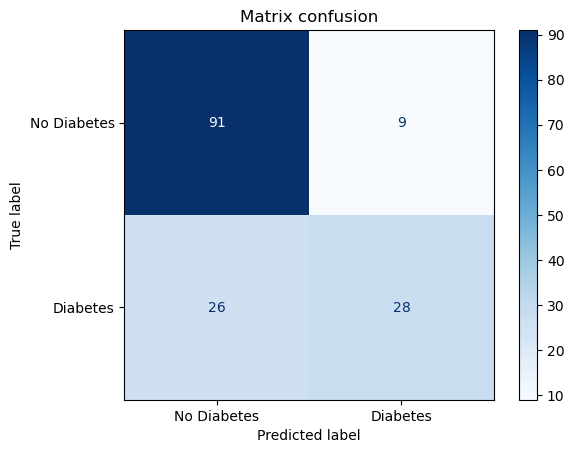

In [36]:
ConfusionMatrixDisplay.from_estimator(pip, X_test, y_test, cmap='Blues',display_labels=['No Diabetes','Diabetes'],values_format='d')
plt.title('Matrix confusion')
plt.grid(False)
plt.show()

In [26]:
print('Training Accuracy:', accuracy_score(y_train, pip.predict(X_train)))
print('Test Accuracy :', accuracy_score(y_test, pip.predict(X_test)))

Training Accuracy: 0.7785016286644951
Test Accuracy : 0.7727272727272727


# 8.Hyperparameter Tuning :
Optimisation des hyperparamètres

In [ ]:
params={
    'svm__kernel':['linear','rbf'],
    'svm__C':[0.1 , 1 , 10, 100],
    'svm__class_weight': [None, 'balanced']
}

cv=StratifiedKFold (
    n_splits = 5,
    shuffle = True,
    random_state = 42
)

grid=GridSearchCV (
    estimator=pip,
    param_grid=params,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
)

grid.fit(X_train, y_train)
print("best parameters:\n", grid.best_params_)
print("\n best f1 CV :", grid.best_score_)


best parameters:
 {'svm__C': 1, 'svm__class_weight': 'balanced', 'svm__kernel': 'rbf'}

 best f1 CV : 0.68045161485495


# 9. Final Model Evaluation
Évaluation finale du modèle optimisé

In [28]:
best_model= grid.best_estimator_
new_y_predict = best_model.predict(X_test)

accuracy = accuracy_score(y_test,new_y_predict)
precision = precision_score(y_test,new_y_predict,zero_division=0)
recall = recall_score(y_test, new_y_predict ,zero_division=0)
F1 = f1_score(y_test, new_y_predict , zero_division=0)

print(f"Accuracy :{accuracy:.4f}")
print(f"Precision :{precision:.4f}")
print(f"Recall :{recall:.4f}")
print(f"F1-score :{F1:.4f}")

Accuracy :0.6948
Precision :0.5593
Recall :0.6111
F1-score :0.5841


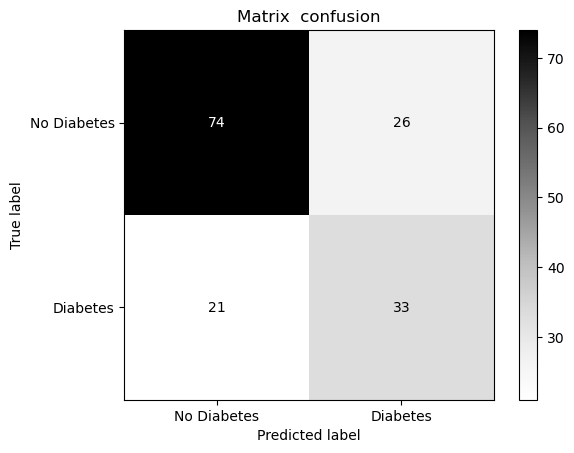

In [37]:
ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test, cmap='Grays',display_labels=['No Diabetes', 'Diabetes'],
    values_format='d')
plt.title('Matrix  confusion')
plt.grid(False)
plt.show()

In [32]:


print("\n Classification Report:\n",classification_report(
    y_test, 
    new_y_predict,
    zero_division=0
))


 Classification Report:
               precision    recall  f1-score   support

           0       0.78      0.74      0.76       100
           1       0.56      0.61      0.58        54

    accuracy                           0.69       154
   macro avg       0.67      0.68      0.67       154
weighted avg       0.70      0.69      0.70       154



In [33]:
print("\nInitial Model F1:", f1_score(y_test, y_predict))
print("Optimized Model F1:", f1_score(y_test, new_y_predict))


Initial Model F1: 0.6153846153846154
Optimized Model F1: 0.584070796460177


# 10.Precision-Recall Curve

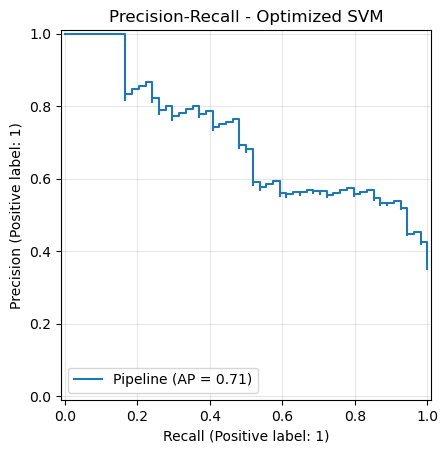

In [43]:

PrecisionRecallDisplay.from_estimator(
    best_model,
    X_test,
    y_test
)

plt.title('Precision-Recall - Optimized SVM')
plt.grid(alpha=0.3)
plt.show()

# 11.ROC Curve

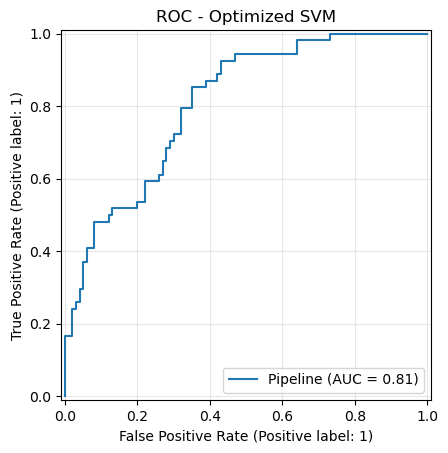

In [44]:
RocCurveDisplay.from_estimator(
    best_model,
    X_test,
    y_test
)

plt.title('ROC - Optimized SVM')
plt.grid(alpha=0.3)
plt.show()


# 12. Initial vs Optimized Metrics Comparison

(0.0, 1.0)

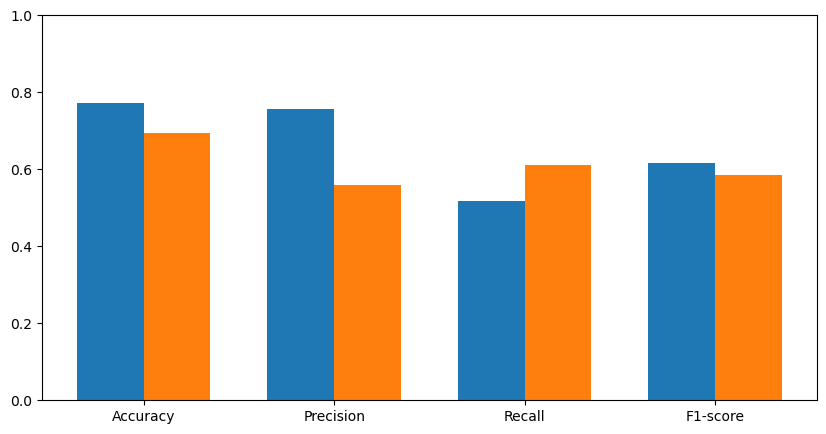

In [46]:
metrics=['Accuracy', 'Precision', 'Recall', 'F1-score']

initial_scores = [0.7727, 0.7568, 0.5185, 0.6154]
optimized_scores = [0.6948, 0.5593, 0.6111, 0.5841]

x=np.arange(len(metrics))
width=0.35

plt.figure(figsize=(10,5))
plt.bar(x - width/2, initial_scores, width, label='Initial SVM')
plt.bar(x + width/2, optimized_scores, width, label='Optimized SVM')

plt.xticks(x,metrics)
plt.ylim(0,1)


# 13. Model Saving and Loading
Sauvegarde et chargement du modèle

In [47]:
with open('model_pipeline.pkl', 'wb' ) as file:
    pickle.dump(best_model, file)
with open('model_pipeline.pkl', 'rb') as file:
    loaded = pickle.load(file)
print('Rechargé identique :' , (loaded.predict(X_test)== new_y_predict).all())

Rechargé identique : True
